Upload your California Housing CSV dataset.


Saving housing.csv to housing (4).csv

Dataset loaded successfully!

========== FIRST 5 RECORDS ==========
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462       

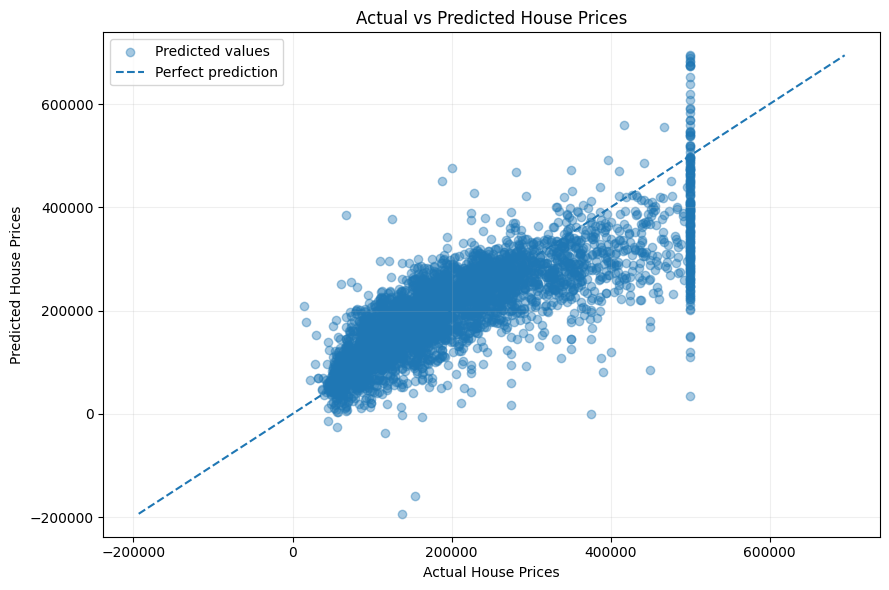

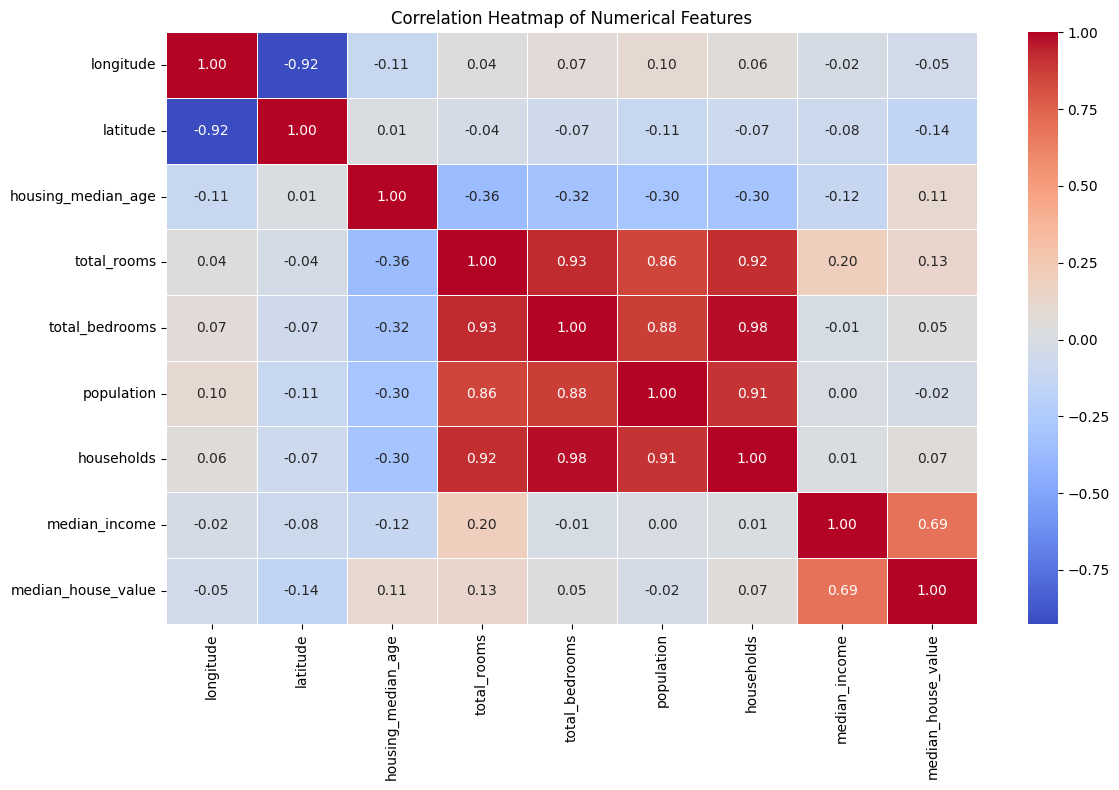


========== ACTUAL VS PREDICTED PRICES ==========
   Actual Price  Predicted Price
0       47700.0         54261.03
1       45800.0        124430.92
2      500001.0        255694.96
3      218600.0        268208.01
4      278000.0        262975.01
5      158700.0        139811.88
6      198200.0        290871.00
7      157500.0        228470.46
8      340000.0        256712.36
9      446600.0        408129.44

Prediction results saved successfully!

========== FINAL SUMMARY ==========
Dataset: housing (4).csv
Target column: median_house_value
Total records used: 20640
Number of input features: 12
Training records: 16512
Testing records: 4128
Algorithm: Linear Regression
MSE: 4908290571.35
RMSE: 70059.19
R2 Score: 0.6254


In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Upload your California Housing CSV dataset.")

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("\nDataset loaded successfully!")

print("\n========== FIRST 5 RECORDS ==========")
print(df.head())

print("\n========== DATASET SHAPE ==========")
print(df.shape)

print("\n========== COLUMN NAMES ==========")
print(df.columns.tolist())

print("\n========== DATA TYPES ==========")
print(df.dtypes)

print("\n========== DATASET INFORMATION ==========")
df.info()

print("\n========== MISSING VALUES BEFORE CLEANING ==========")
print(df.isnull().sum())

print("\n========== DUPLICATE RECORDS ==========")
print(df.duplicated().sum())

print("\n========== STATISTICAL SUMMARY ==========")
print(df.describe(include="all"))


df = df.drop_duplicates().copy()


target_column = "median_house_value"

if target_column not in df.columns:
    raise ValueError(
        "The dataset must contain the column "
        "'median_house_value'. Please upload the correct dataset."
    )


X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()


valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].copy()

print("\n========== DATA AFTER REMOVING DUPLICATES ==========")
print("Number of records:", len(df))



X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\n========== DATA SPLITTING ==========")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


numerical_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()


for col in numerical_columns:

    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)


for col in categorical_columns:

    mode_values = X_train[col].mode()

    if not mode_values.empty:
        mode_value = mode_values.iloc[0]
    else:
        mode_value = "Unknown"

    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

print("\n========== MISSING VALUES AFTER CLEANING ==========")
print("Training data:")
print(X_train.isnull().sum())

print("\nTesting data:")
print(X_test.isnull().sum())



X_train = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)


X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("\n========== INPUT FEATURES ==========")
print(X_train.columns.tolist())

print("Number of input features:", X_train.shape[1])



scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed successfully!")


model = LinearRegression()

model.fit(X_train_scaled, y_train)

print("\nLinear Regression model trained successfully!")



y_pred = model.predict(X_test_scaled)


mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")

print(f"Mean Squared Error (MSE): {mse:.2f}")

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

print(f"R-squared (R2) Score: {r2:.4f}")



plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4,
    label="Predicted values"
)


min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


correlation_df = df.select_dtypes(
    include=np.number
).copy()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()



results = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred
})

print("\n========== ACTUAL VS PREDICTED PRICES ==========")
print(results.head(10).round(2))


results.to_csv("house_price_predictions.csv", index=False)

print("\nPrediction results saved successfully!")



print("\n========== FINAL SUMMARY ==========")

print("Dataset:", filename)
print("Target column:", target_column)
print("Total records used:", len(X))
print("Number of input features:", X_train.shape[1])
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Algorithm: Linear Regression")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")




